# Impact of instance dependent normalization in the Sherrington Kirkpatrick model

Compare the original Gaussian Ising instances (normalized and raw), newly generated random-field SK instances, and the same original instances converted to SK couplings. **All spectral gaps use $\beta=4$**, Metropolis acceptance ($a=\infty$), and moves `local1`, `uniform`, `layden`. Both SK variants explicitly use `local_fields=True` ($J_{ij}\sim\mathcal N(0,1/n)$ and $h_i\sim\mathcal N(0,1)$). New HDF5 files are stored in `./sk_variants/`, alongside the notebook.


## 1. Import

In [1]:
import sys
if ".." not in sys.path:
    sys.path.append("..")  # Make the local package visible without an editable installation.

from pathlib import Path
import h5py
import numpy as np
import pandas as pd
from monaqa2.data.filename import SPECTRAL_GAP_FILE
from monaqa2.data.instances import load_instances
from monaqa2.mcmc.model import RandomSherringtonKirkpatrickModel
from monaqa2.mcmc.transition import create_transition_matrix
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

## 2. Spectral gaps of the instance-dependent normalized instances

Load `spectral_gaps_merged.pkl` into `normalized_spectral_gaps[move][n][idx]`. Missing values remain `NaN`.

In [2]:
MOVES = ("local1", "uniform", "layden")
BETA, A, N_INSTANCES, SEED = 4.0, np.inf, 100, 2026
NS_ALL, NS_GAPS = range(3, 10+1), range(3, 7+1)
OUT = Path.cwd() / "sk_variants"  # Launch the notebook from its directory
OUT.mkdir(exist_ok=True)
UNNORMALIZED_FILE = OUT / "spectral_gaps_unnormalized.hdf5"
SK_INSTANCES_FILE = OUT / "ising_sk_instances.hdf5"
SK_NEWINST_GAPS_FILE = OUT / "spectral_gaps_sk_newinst.hdf5"
SK_OLDINST_GAPS_FILE = OUT / "spectral_gaps_sk_oldinst.hdf5"

normalized_spectral_gaps = {m: {n: np.full(N_INSTANCES, np.nan) for n in NS_ALL} for m in MOVES}
raw = pd.read_pickle(SPECTRAL_GAP_FILE)
rows = raw[raw["proposal"].isin(MOVES) & (raw["a"] == A) & np.isclose(raw["beta"], BETA)]
if rows.duplicated(["proposal", "n", "idx"]).any():
    raise ValueError("Duplicate normalized spectral gap for a move/n/idx.")
for row in rows.itertuples(index=False):
    if row.n in NS_ALL and 0 <= row.idx < N_INSTANCES:
        normalized_spectral_gaps[row.proposal][row.n][row.idx] = row.delta
print({m: {n: int(np.isfinite(v).sum()) for n, v in by_n.items()}
       for m, by_n in normalized_spectral_gaps.items()})

{'local1': {3: 100, 4: 100, 5: 100, 6: 100, 7: 100, 8: 100, 9: 100, 10: 100}, 'uniform': {3: 100, 4: 100, 5: 100, 6: 100, 7: 100, 8: 100, 9: 100, 10: 100}, 'layden': {3: 100, 4: 100, 5: 100, 6: 100, 7: 100, 8: 100, 9: 100, 10: 100}}


## 3. Spectral gaps of the unnormalized instances

Reuse the existing Gaussian instances but set `rescaled=False` for both Metropolis acceptance and quantum proposals. At $\beta=4$, compute only missing $n=3,\ldots,6$ gaps and cache them in `sk_variants/spectral_gaps_unnormalized.hdf5`.

In [3]:
NS_GAPS = range(3, 6+1)

In [4]:
def cached_gaps(path, loader, ensemble):
    out = {move: {} for move in MOVES}
    path.parent.mkdir(parents=True, exist_ok=True)
    meta = dict(beta=BETA, a="inf", instances=N_INSTANCES, rescaled=False, ensemble=ensemble)
    with h5py.File(path, "a") as f:
        if len(f) and any(k not in f.attrs for k in meta):
            raise ValueError(f"Cache lacks metadata: {path}")
        for k, v in meta.items():
            if k in f.attrs and f.attrs[k] != v:
                raise ValueError(f"Cache setting mismatch: {path} / {k}")
            f.attrs[k] = v
        for n in NS_GAPS:
            ds = {m: f.require_group(m).require_dataset(str(n), (N_INSTANCES,), float,
                  exact=True, fillvalue=np.nan) for m in MOVES}
            values = {m: ds[m][:] for m in MOVES}
            for idx in range(N_INSTANCES):
                missing = [m for m in MOVES if not np.isfinite(values[m][idx])]
                if not missing:
                    continue
                model = loader(n, idx)
                for move in missing:
                    Q = create_transition_matrix(move, model, BETA, a=A, rescaled=False)
                    eigenvalues = np.linalg.eigvalsh(np.sqrt(np.maximum(Q * Q.T, 0)))
                    gap = float(1 - np.max(np.abs(eigenvalues[:-1])))
                    ds[move][idx] = values[move][idx] = gap
                f.flush()  # Resume safely after interruption
            for move in MOVES:
                out[move][n] = values[move]
            print(f"{ensemble}: n={n}, {np.isfinite(values[MOVES[0]]).sum()}/{N_INSTANCES}")
    return out

unnormalized_spectral_gaps = cached_gaps(UNNORMALIZED_FILE, load_instances, "raw_gaussian")

raw_gaussian: n=3, 100/100
raw_gaussian: n=4, 100/100
raw_gaussian: n=5, 100/100
raw_gaussian: n=6, 100/100


## 4. Spectral gaps of the new SK model

Generate 100 independent random-field SK instances per $n=3,\ldots,10$ (explicit `local_fields=True`), saved to `sk_variants/ising_sk_instances.hdf5`. Compute $\beta=4$ gaps for $n=3,\ldots,6$, cached in `sk_variants/spectral_gaps_sk_newinst.hdf5`.


In [5]:
SK_INSTANCES_FILE.parent.mkdir(parents=True, exist_ok=True)
with h5py.File(SK_INSTANCES_FILE, "a") as f:
    meta = dict(seed=SEED, instances=N_INSTANCES, local_fields=True)
    if len(f) and any(k not in f.attrs for k in meta):
        raise ValueError("Existing SK instances lack metadata.")
    for k, v in meta.items():
        if k in f.attrs and f.attrs[k] != v:
            raise ValueError(f"SK instance cache mismatch: {k}")
        f.attrs[k] = v
    group = f.require_group("coefficients")
    for n in NS_ALL:
        size = n + n * (n - 1) // 2
        ds = group.require_dataset(str(n), (size, N_INSTANCES), float,
                                   exact=True, fillvalue=np.nan)
        for idx in range(N_INSTANCES):
            if np.isfinite(ds[:, idx]).all():
                continue
            model = RandomSherringtonKirkpatrickModel(
                n, local_fields=True, seed=SEED + 1000*n + idx)
            ds[:, idx] = np.r_[model.h, model.J[np.triu_indices(n, k=1)]]
        f.flush()


def load_sk_instance(n, idx):
    with h5py.File(SK_INSTANCES_FILE, "r") as f:
        coefficients = f["coefficients"][str(n)][:, idx]
    return RandomSherringtonKirkpatrickModel.from_coefficients(n, coefficients)

sk_newinst_spectral_gaps = cached_gaps(SK_NEWINST_GAPS_FILE, load_sk_instance, "sk_newinst_fields_true")

sk_newinst_fields_true: n=3, 100/100
sk_newinst_fields_true: n=4, 100/100
sk_newinst_fields_true: n=5, 100/100
sk_newinst_fields_true: n=6, 100/100


## 5. Spectral gaps of the unnormalized instances turned into SK model

Reuse the original Gaussian instances and convert $J\mapsto J/\sqrt{n}$, keeping their local fields (`local_fields=True`). At $\beta=4$, calculate gaps for $n=3,\ldots,6$ and cache only `sk_variants/spectral_gaps_sk_oldinst.hdf5` (no second instance dataset).

In [6]:
def load_old_sk_instance(n, idx):
    return load_instances(n, idx).to_sk(local_fields=True)

sk_oldinst_spectral_gaps = cached_gaps(
    SK_OLDINST_GAPS_FILE, load_old_sk_instance, "sk_oldinst_fields_true")

sk_oldinst_fields_true: n=3, 100/100
sk_oldinst_fields_true: n=4, 100/100
sk_oldinst_fields_true: n=5, 100/100
sk_oldinst_fields_true: n=6, 100/100


## 6. Spectral-gap distributions across models

At $\beta=4$, one violin plot for each move compares the four model families for $n=3,\ldots,6$. Following `plot_table.py`, the y-axis displays the spectral gap $\delta$ on a logarithmic scale.


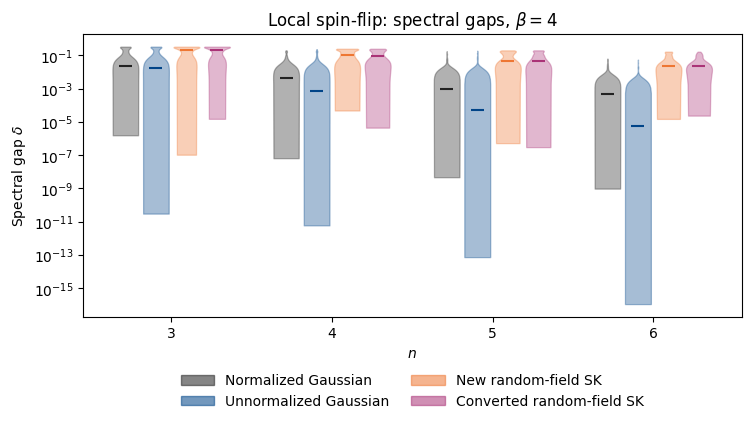

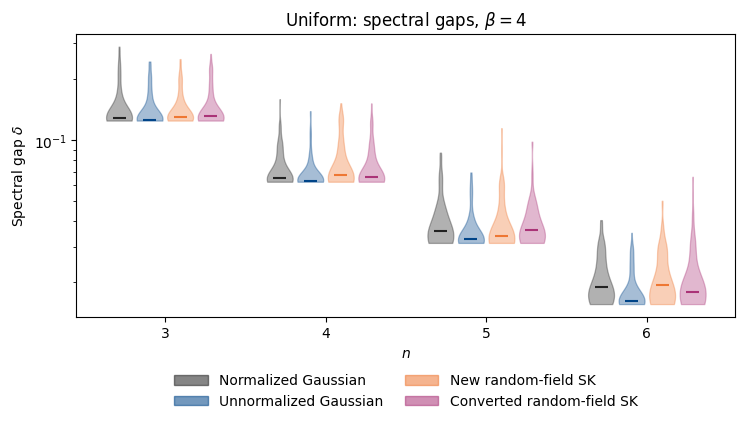

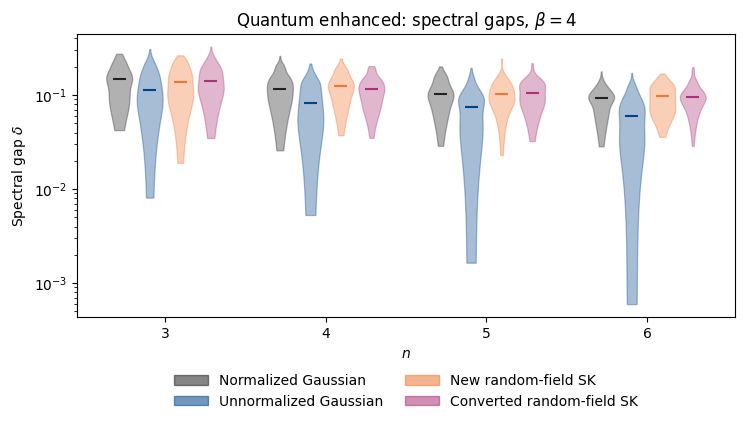

In [7]:
ENSEMBLES = {
    "Normalized Gaussian": normalized_spectral_gaps,
    "Unnormalized Gaussian": unnormalized_spectral_gaps,
    "New random-field SK": sk_newinst_spectral_gaps,
    "Converted random-field SK": sk_oldinst_spectral_gaps,
}
# Match the restrained black/navy/orange/magenta palette in plot_table.py.
COLORS = dict(zip(ENSEMBLES, ("#222222", "#004488", "#EE7733", "#AA3377")))
MOVE_LABELS = {"local1": "Local spin-flip", "uniform": "Uniform", "layden": "Quantum enhanced"}

for move in MOVES:
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    width = 0.19
    for j, (label, gaps) in enumerate(ENSEMBLES.items()):
        for n in NS_GAPS:
            values = np.asarray(gaps[move].get(n, []), dtype=float)
            values = values[np.isfinite(values) & (values > 0)]
            if not values.size:
                continue
            pos = n + (j - 1.5) * width
            if len(values) < 2 or np.ptp(values) < 1e-12 * max(1.0, np.median(values)):
                ax.scatter(pos, np.median(values), color=COLORS[label], s=26, zorder=4)
                continue
            violin = ax.violinplot([values], positions=[pos], widths=width * 0.85,
                                   showmedians=True, showextrema=False)
            violin["bodies"][0].set(facecolor=COLORS[label], edgecolor=COLORS[label],
                                      alpha=0.35, linewidth=0.9)
            violin["cmedians"].set(color=COLORS[label], linewidth=1.5)

    ax.set_yscale("log")
    ax.set_xticks(list(NS_GAPS))
    ax.set_xlabel(r"$n$")
    ax.set_ylabel(r"Spectral gap $\delta$")
    ax.set_title(rf"{MOVE_LABELS[move]}: spectral gaps, $\beta={BETA:g}$")
    ax.set_xlim(min(NS_GAPS) - 0.55, max(NS_GAPS) + 0.55)
    ax.set_axisbelow(True)
    ax.grid(False)
    ax.legend([Patch(facecolor=COLORS[label], edgecolor=COLORS[label], alpha=0.55)
               for label in ENSEMBLES], list(ENSEMBLES),
              frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18),
              ncol=2, borderaxespad=0.0, handlelength=2.4, columnspacing=1.6)
    fig.subplots_adjust(bottom=0.29)
    plt.show()


## 7. Diagnostics (copyable tables)

All statistics use the **actual spectral gaps** $\delta$ (not their logarithms). Each line reports the number of positive finite gaps, missing values, nonpositive gaps, and the distribution's median, quartiles, mean and extremes. The second table compares **model medians for the same move and $n$**; these are *ratios of medians*, not paired instance-by-instance ratios. The last table reports the instance-dependent normalization factor and the equivalent raw-energy inverse temperature $\beta_{\mathrm{raw}}=4\alpha$.

In [8]:
# Plain-text tables: easy to read and to paste into a discussion.
def gap_summary(values):
    values = np.asarray(values, dtype=float).ravel()
    finite = values[np.isfinite(values)]
    valid = finite[(finite > 0) & (finite <= 1 + 1e-8)]
    q25, median, q75 = np.percentile(valid, [25, 50, 75]) if valid.size else (np.nan,) * 3
    return dict(
        count=len(valid), missing=max(N_INSTANCES - len(values), 0) + np.sum(~np.isfinite(values)),
        nonpositive=np.sum(finite <= 0), above_one=np.sum(finite > 1 + 1e-8),
        median=median, q25=q25, q75=q75,
        mean=np.mean(valid) if valid.size else np.nan,
        minimum=np.min(valid) if valid.size else np.nan,
        maximum=np.max(valid) if valid.size else np.nan,
    )

records = []
for move in MOVES:
    for n in NS_GAPS:
        for model, gaps in ENSEMBLES.items():
            records.append(dict(move=move, n=n, model=model,
                                **gap_summary(gaps[move].get(n, []))))
summary = pd.DataFrame(records)
fmt = lambda x: f"{x:.4g}"

print(f"SPECTRAL-GAP DIAGNOSTICS | beta={BETA:g} | expected={N_INSTANCES} instances per n")
print("Missing = absent/NaN/Inf; nonpositive or >1 gaps are reported separately and excluded from statistics.")
for move in MOVES:
    print(f"\n=== {MOVE_LABELS[move]} ({move}) ===")
    print(summary.loc[summary.move == move, [
        "n", "model", "count", "missing", "nonpositive", "above_one",
        "median", "q25", "q75", "mean", "minimum", "maximum"
    ]].to_string(index=False, float_format=fmt))

# Model comparison (within the same move and n), without comparing different moves.
ratios = []
for (move, n), group in summary.groupby(["move", "n"], sort=False):
    med = group.set_index("model")["median"]
    base = med["Normalized Gaussian"]
    safe_ratio = lambda a, b: a / b if np.isfinite(a) and np.isfinite(b) and b > 0 else np.nan
    ratios.append(dict(move=move, n=n,
                       raw_vs_norm=safe_ratio(med["Unnormalized Gaussian"], base),
                       sk_new_vs_norm=safe_ratio(med["New random-field SK"], base),
                       sk_old_vs_norm=safe_ratio(med["Converted random-field SK"], base),
                       sk_new_vs_old=safe_ratio(med["New random-field SK"],
                                                med["Converted random-field SK"])))
print("\n=== RATIOS OF MODEL MEDIAN GAPS (same move and n) ===")
print(pd.DataFrame(ratios).to_string(index=False, float_format=fmt))

# Check the actual instance-by-instance normalization (not just its large-n approximation).
alpha_rows = []
for n in NS_GAPS:
    alpha = np.array([load_instances(n, i).alpha for i in range(N_INSTANCES)])
    alpha_rows.append(dict(n=n, alpha_median=np.median(alpha),
                           alpha_q25=np.percentile(alpha, 25),
                           alpha_q75=np.percentile(alpha, 75),
                           alpha_typical=np.sqrt(2 / (n + 1)),
                           beta_raw_median=BETA * np.median(alpha)))
print("\n=== ORIGINAL-INSTANCE NORMALIZATION (beta_normalized=4) ===")
print(pd.DataFrame(alpha_rows).to_string(index=False, float_format=fmt))

SPECTRAL-GAP DIAGNOSTICS | beta=4 | expected=100 instances per n
Missing = absent/NaN/Inf; nonpositive or >1 gaps are reported separately and excluded from statistics.

=== Local spin-flip (local1) ===
 n                     model  count  missing  nonpositive  above_one    median       q25       q75     mean   minimum  maximum
 3       Normalized Gaussian    100        0            0          0    0.0223  0.002471    0.2298   0.1083 1.561e-06   0.3325
 3     Unnormalized Gaussian    100        0            0          0   0.01622 0.0006649    0.2385   0.1082 3.053e-11   0.3333
 3       New random-field SK    100        0            0          0    0.2139   0.02643     0.318   0.1812 1.062e-07   0.3333
 3 Converted random-field SK    100        0            0          0    0.2225   0.03516    0.3256   0.1932 1.522e-05   0.3333
 4       Normalized Gaussian    100        0            0          0  0.004283 0.0002142   0.01974  0.02563 6.534e-08   0.2008
 4     Unnormalized Gaussian    100 